In [1]:
# import os
# os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import time
import copy

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

import torch
import torch.nn as nn

from utils import get_opt, get_loaders, eval_ppl
from predictor_definitions import LogisticRegression, MLPClassifier

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
layers_to_keep = (0, 1, 23)

# Loading

## Model

In [3]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
# model_name = "HuggingFaceTB/SmolLM2-360M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Predictors

In [4]:
for i, layer in enumerate(model.model.layers):
    if i in layers_to_keep: 
        continue
    layer.predictor = {}
    layer.predictor['lr'] = joblib.load(f'predictors/cls_model_layer{i}.pkl')
    layer.predictor['nn'] = joblib.load(f'predictors/cls_model_mlp_layer{i}.pkl')

## Data

In [5]:
# n_samples = 32

# dataloader, testloader = get_loaders(
#     "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
# )

In [6]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


# Router

In [7]:
class MLPRouter(nn.Module):
    def __init__(self, predictor, mlp, save_bitmap=False):
        super().__init__()
        self.predictor = predictor
        self.mlp = mlp
        self.n_total = 0
        self.n_mlp = 0
        self.save_bitmap = save_bitmap
        if save_bitmap:
            self.bitmap = []
        
    def forward(self, x):
        use_mlp = self.predictor.predict(x.to(torch.float)).astype(bool)
        # print(use_mlp.flatten().sum())
        bsz, seq_len, dim = x.shape
        x_flat = x.view(-1, dim)
        use_mlp_flat = use_mlp.flatten()  # shape: (bsz * seq_len)
        self.n_mlp += use_mlp_flat.sum()
        self.n_total += use_mlp_flat.size
        # Apply MLP only to selected tokens
        out = torch.zeros_like(x_flat)  # same shape as input
        if use_mlp_flat.any():
            selected = x_flat[use_mlp_flat]  # (N_selected, dim)
            mlp_out = self.mlp(selected)     # (N_selected, dim)
            out[use_mlp_flat] = mlp_out      # insert results
            if self.save_bitmap:
                self.bitmap.extend(use_mlp_flat.tolist())

        return out.view(bsz, seq_len, dim)
        

In [10]:
# layer = model.model.layers[5]
# predictor = layer.predictor['lr']
# mlp_copy = copy.deepcopy(layer.mlp)
# layer.mlp = MLPRouter(predictor, mlp_copy)
# ppl = eval_ppl(model, wiki_testloader, device=DEV)
# ppl

# Evaluate pruned model

In [8]:
def eval_model(use_router='', results_router=None, layer_stats=None):
    if layer_stats is None:
        layer_stats = pd.DataFrame()
    if results_router is None:
        results_router = pd.DataFrame(columns=["perplexity", "inference_time"])

    if use_router:
        predictor_quality = pd.read_csv('prediction_results.csv', index_col=0)
        auc_col = 'AUC' if use_router == 'lr' else 'AUC_mlp'
        
        # replace MLP with router
        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue
            predictor = layer.predictor[use_router]
            mlp_copy = copy.deepcopy(layer.mlp)
            layer.mlp = MLPRouter(predictor, mlp_copy)
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_router.loc[use_router] = [ppl, t]

    # repair
    if use_router:
        sum_n_total = sum_n_skipped = 0
        column_name = use_router

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue

            n_total = layer.mlp.n_total
            n_skipped = n_total - layer.mlp.n_mlp
            skip_ratio = n_skipped / n_total if n_total > 0 else 0

            sum_n_skipped += n_skipped

            layer_stats.at[i, column_name] = skip_ratio
            layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

        sum_n_total = n_total * len(model.model.layers)
        global_skip_ratio = sum_n_skipped / sum_n_total
        layer_stats.at['all', column_name] = global_skip_ratio

    return results_router, layer_stats

In [9]:
results_router = pd.DataFrame(columns=["perplexity", "inference_time"])

results_router, layer_stats = eval_model('lr', results_router=results_router)
results_router, layer_stats = eval_model('nn', results_router=results_router, layer_stats=layer_stats)
results_router, layer_stats = eval_model('', results_router=results_router, layer_stats=layer_stats)
results_router.to_csv('results_router.csv')
results_router

OutOfMemoryError: CUDA out of memory. Tried to allocate 128.00 MiB. GPU 0 has a total capacity of 39.49 GiB of which 31.81 MiB is free. Process 1658773 has 33.39 GiB memory in use. Including non-PyTorch memory, this process has 6.06 GiB memory in use. Of the allocated memory 5.08 GiB is allocated by PyTorch, and 500.10 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

## Ratio of tokens routed around the MLP

In [32]:
layer_stats

,lr,nn
2,0.356693,0.446197
3,0.270145,0.438460
4,0.172957,0.407382
5,0.000102,0.771712
6,0.000000,0.414026
7,0.012461,0.548633
8,0.000003,0.367237
9,0.012883,0.331992
10,0.000000,0.086766
11,0.000000,0.038238


# Using only predictors with higher AUC

In [33]:
def eval_model_with_AUC_threshold(use_router='', results_router=None, layer_stats=None, auc_thr=0.75):
    if layer_stats is None:
        layer_stats = pd.DataFrame()
    if results_router is None:
        results_router = pd.DataFrame(columns=["perplexity", "inference_time"])

    if use_router:
        predictor_quality = pd.read_csv('all_prediction_results.csv', index_col=0)
        auc_col = 'AUC' if use_router == 'lr' else 'AUC_mlp'
        
        # replace MLP with router only if the AUC is high enough for the layer
        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep or predictor_quality.loc[i, auc_col] < auc_thr:
                continue
            predictor = layer.predictor[use_router]
            mlp_copy = copy.deepcopy(layer.mlp)
            layer.mlp = MLPRouter(predictor, mlp_copy)
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_router.loc[use_router] = [ppl, t]

    # repair
    if use_router:
        sum_n_total = sum_n_skipped = 0
        column_name = use_router

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep or predictor_quality.loc[i, auc_col] < auc_thr:
                continue

            n_total = layer.mlp.n_total
            n_skipped = n_total - layer.mlp.n_mlp
            skip_ratio = n_skipped / n_total if n_total > 0 else 0

            sum_n_skipped += n_skipped

            layer_stats.at[i, column_name] = skip_ratio
            layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

        sum_n_total = n_total * len(model.model.layers)
        global_skip_ratio = sum_n_skipped / sum_n_total
        layer_stats.at['all', column_name] = global_skip_ratio

    return results_router, layer_stats

In [34]:
results_router_thr = pd.DataFrame(columns=["perplexity", "inference_time"])

results_router_thr, layer_stats_thr = eval_model_with_AUC_threshold('lr', results_router=results_router_thr, auc_thr=0.8)
results_router_thr, layer_stats_thr = eval_model_with_AUC_threshold('nn', results_router=results_router_thr, layer_stats=layer_stats_thr, auc_thr=0.8)
results_router_thr, layer_stats_thr = eval_model_with_AUC_threshold('', results_router=results_router_thr, layer_stats=layer_stats_thr, auc_thr=0.8)
results_router_thr.to_csv('results_router_thr.csv')
results_router_thr

,perplexity,inference_time
lr,9.461728,9.022177
nn,15.059263,8.684023
,7.260689,9.305189


In [39]:
# stare vysledky
results_router_thr = pd.DataFrame(columns=["perplexity", "inference_time"])

results_router_thr, layer_stats_thr = eval_model_with_AUC_threshold('lr', results_router=results_router_thr, auc_thr=0.8)
results_router_thr, layer_stats_thr = eval_model_with_AUC_threshold('nn', results_router=results_router_thr, layer_stats=layer_stats_thr, auc_thr=0.8)
results_router_thr, layer_stats_thr = eval_model_with_AUC_threshold('', results_router=results_router_thr, layer_stats=layer_stats_thr, auc_thr=0.8)
results_router_thr.to_csv('results_router_thr.csv')
results_router_thr

,perplexity,inference_time
lr,178.115570,9.344595
nn,427.999298,9.386919
,7.260689,9.345299


In [35]:
layer_stats_thr

,lr,nn
2,0.356693,0.446197
3,0.270145,0.438460
4,0.172957,0.407382
19,0.438354,0.621638
20,0.097033,0.396837
21,0.190344,0.776684
22,0.817234,0.828415
all,0.097615,0.195305
5,NaN,0.771712


---
# Top-k router

In [13]:
class MLPRouterTopK(nn.Module):
    def __init__(self, predictor, mlp, k=0.7):
        super().__init__()
        self.predictor = predictor
        self.mlp = mlp
        self.k = k
        self.n_total = 0
        self.n_mlp = 0
        
    def forward(self, x):
        # compute logits
        use_mlp_probs = torch.Tensor(self.predictor.predict_proba(x.to(torch.float)))
        bsz, seq_len, dim = x.shape
        x_flat = x.view(-1, dim)

        k_per_row = max(1, int(seq_len * self.k))  # ensure at least 1
        selected_idx = torch.topk(use_mlp_probs, k_per_row, dim=1).indices.flatten()  # (bsz, k_per_row)
        
        self.n_mlp += selected_idx.numel()
        self.n_total += use_mlp_probs.numel()
        # Apply MLP only to selected tokens
        out = torch.zeros_like(x_flat)  # same shape as input
        if selected_idx.numel():
            selected = x_flat[selected_idx]  # (N_selected, dim)
            mlp_out = self.mlp(selected)     # (N_selected, dim)
            out[selected_idx] = mlp_out      # insert results

        return out.view(bsz, seq_len, dim)
        

In [14]:
def eval_model_topk(use_router='', results_router=None, layer_stats=None, k=0.7):
    if layer_stats is None:
        layer_stats = pd.DataFrame()
    if results_router is None:
        results_router = pd.DataFrame(columns=["perplexity", "inference_time"])

    if use_router:
        predictor_quality = pd.read_csv('all_prediction_results.csv', index_col=0)
        auc_col = 'AUC' if use_router == 'lr' else 'AUC_mlp'
        
        # replace MLP with router only if the AUC is high enough for the layer
        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue
            predictor = layer.predictor[use_router]
            mlp_copy = copy.deepcopy(layer.mlp)
            layer.mlp = MLPRouterTopK(predictor, mlp_copy, k=k)
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_router.loc[use_router] = [ppl, t]

    # repair
    if use_router:
        sum_n_total = sum_n_skipped = 0
        column_name = use_router

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue

            n_total = layer.mlp.n_total
            n_skipped = n_total - layer.mlp.n_mlp
            skip_ratio = n_skipped / n_total if n_total > 0 else 0

            sum_n_skipped += n_skipped

            layer_stats.at[i, column_name] = skip_ratio
            layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

        sum_n_total = n_total * len(model.model.layers)
        global_skip_ratio = sum_n_skipped / sum_n_total
        layer_stats.at['all', column_name] = global_skip_ratio

    return results_router, layer_stats

In [18]:
results_router_top70 = pd.DataFrame(columns=["perplexity", "inference_time"])

results_router_top70, layer_stats_top70 = eval_model_topk('lr', results_router=results_router_top70)
results_router_top70, layer_stats_top70 = eval_model_topk('nn', results_router=results_router_top70, layer_stats=layer_stats_top70)
results_router_top70, layer_stats_top70 = eval_model_topk('', results_router=results_router_top70, layer_stats=layer_stats_top70)
results_router_top70.to_csv('results_router_top70.csv')
results_router_top70

,perplexity,inference_time
lr,169.028595,8.997414
nn,252.139633,9.041593
,7.260689,9.297124


In [19]:
layer_stats_top70

,lr,nn
2,0.300049,0.300049
3,0.300049,0.300049
4,0.300049,0.300049
5,0.300049,0.300049
6,0.300049,0.300049
7,0.300049,0.300049
8,0.300049,0.300049
9,0.300049,0.300049
10,0.300049,0.300049
11,0.300049,0.300049


In [16]:
results_router_top80 = pd.DataFrame(columns=["perplexity", "inference_time"])

results_router_top80, layer_stats_top80 = eval_model_topk('lr', results_router=results_router_top80, k=0.8)
results_router_top80, layer_stats_top80 = eval_model_topk('nn', results_router=results_router_top80, layer_stats=layer_stats_top80, k=0.8)
results_router_top80, layer_stats_top80 = eval_model_topk('', results_router=results_router_top80, layer_stats=layer_stats_top80, k=0.8)
results_router_top80.to_csv('results_router_top80.csv')
results_router_top80

,perplexity,inference_time
lr,64.782173,13.072218
nn,66.248466,9.408454
,7.260689,9.242539


In [17]:
layer_stats_top80

,lr,nn
2,0.200073,0.200073
3,0.200073,0.200073
4,0.200073,0.200073
5,0.200073,0.200073
6,0.200073,0.200073
7,0.200073,0.200073
8,0.200073,0.200073
9,0.200073,0.200073
10,0.200073,0.200073
11,0.200073,0.200073


# Visualization of routing

In [13]:
def eval_model(use_router='', results_router=None, layer_stats=None, save_bitmap=False):
    if layer_stats is None:
        layer_stats = pd.DataFrame()
    if results_router is None:
        results_router = pd.DataFrame(columns=["perplexity", "inference_time"])

    if use_router:
        predictor_quality = pd.read_csv('all_prediction_results.csv', index_col=0)
        auc_col = 'AUC' if use_router == 'lr' else 'AUC_mlp'
        
        # replace MLP with router
        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue
            predictor = layer.predictor[use_router]
            mlp_copy = copy.deepcopy(layer.mlp)
            layer.mlp = MLPRouter(predictor, mlp_copy, save_bitmap=save_bitmap)
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_router.loc[use_router] = [ppl, t]

    # repair
    routing_bitmap = []
    if use_router:
        sum_n_total = sum_n_skipped = 0
        column_name = use_router

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue

            n_total = layer.mlp.n_total
            n_skipped = n_total - layer.mlp.n_mlp
            skip_ratio = n_skipped / n_total if n_total > 0 else 0

            sum_n_skipped += n_skipped

            if save_bitmap:
                routing_bitmap.append(layer.mlp.bitmap)

            layer_stats.at[i, column_name] = skip_ratio
            layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

        sum_n_total = n_total * len(model.model.layers)
        global_skip_ratio = sum_n_skipped / sum_n_total
        layer_stats.at['all', column_name] = global_skip_ratio

    return results_router, layer_stats, routing_bitmap

In [14]:
results_router, layer_stats, bitmap_lr = eval_model('lr', save_bitmap=True)
results_router, layer_stats, bitmap_mlp = eval_model('nn', results_router=results_router, layer_stats=layer_stats, save_bitmap=True)
results_router, layer_stats, bitmap = eval_model('', results_router=results_router, layer_stats=layer_stats, save_bitmap=True)

In [41]:
pd.DataFrame(bitmap_lr).to_csv('bitmap_lr.csv')
pd.DataFrame(bitmap_mlp).to_csv('bitmap_mlp.csv')

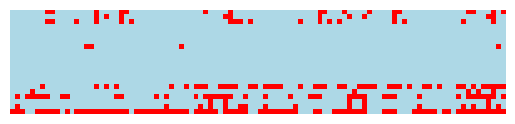

In [50]:
from matplotlib.colors import ListedColormap

# bitmap of routing using LR
bitmap_lr_slice = [row[:100] for row in bitmap_lr]
cmap = ListedColormap(["red", "lightblue"])  # skipped=red
plt.imshow(bitmap_lr_slice, cmap=cmap, interpolation="nearest")
plt.axis("off")
plt.show()

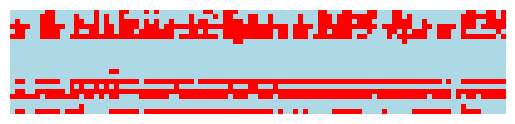

In [51]:
# bitmap of routing using MLP
bitmap_mlp_slice = [row[:100] for row in bitmap_mlp]
cmap = ListedColormap(["red", "lightblue"])  # skipped=red
plt.imshow(bitmap_mlp_slice, cmap=cmap, interpolation="nearest")
plt.axis("off")
plt.show()